In [1]:

import pandas as pd
import numpy as np
from pathlib import Path

# Load Python ground-truth results
gt_file = Path(r"C:\Users\Admin\python_ground_truth_summary.csv")
if not gt_file.exists():
    raise FileNotFoundError(
        "Run the ground-truth section first to create "
        "python_ground_truth_summary.csv"
    )

gt = pd.read_csv(gt_file)

# Create a comparison template
comparison = gt.rename(columns={
    "Metric": "Question",
    "Python Ground Truth": "Python_Answer"
}).copy()

# Enter the actual answers from each model in the next cell
comparison["GPT_Answer"] = np.nan
comparison["Gemini_Answer"] = np.nan

# Add comparison columns
comparison["GPT_Match"] = ""
comparison["Gemini_Match"] = ""
comparison["GPT_Error"] = np.nan
comparison["Gemini_Error"] = np.nan

# Save a template for entering answers
comparison.to_csv("llm_comparison_template.csv", index=False)

print("Created llm_comparison_template.csv")
display(comparison)


Created llm_comparison_template.csv


,Question,Python_Answer,GPT_Answer,Gemini_Answer,GPT_Match,Gemini_Match,GPT_Error,Gemini_Error
0,Total rows,10000.0,NaN,NaN,,,NaN,NaN
1,Total quantity (available values),28763.0,NaN,NaN,,,NaN,NaN
2,Total recorded sales (available values),84547.5,NaN,NaN,,,NaN,NaN
3,Total calculated sales (Quantity × Price Per U...,80064.5,NaN,NaN,,,NaN,NaN
4,Total positive quantity,28763.0,NaN,NaN,,,NaN,NaN
5,Total positive recorded sales,84547.5,NaN,NaN,,,NaN,NaN
6,Total positive calculated sales,80064.5,NaN,NaN,,,NaN,NaN
7,Missing Quantity values,504.0,NaN,NaN,,,NaN,NaN
8,Missing Price Per Unit values,558.0,NaN,NaN,,,NaN,NaN
9,Missing Total Spent values,527.0,NaN,NaN,,,NaN,NaN


In [2]:

# Replace None with the actual answers returned by each model.
# Use the exact metric names shown in the comparison table.

gpt_answers = {
    "Total rows": 10020,
    "Total quantity (available values)": 28785,
    "Total recorded sales (available values)": 848631,
    "Total calculated sales (Quantity × Price Per Unit)": 80075,
    "Total positive quantity": 28813,
    "Total positive recorded sales": 84728,
    "Total positive calculated sales": 80221,
    "Missing Quantity values": 497,
    "Missing Price Per Unit values": 548,
    "Missing Total Spent values": 517,
    "Negative Quantity values": 10,
    "Negative Price Per Unit values": 10,
    "Negative Total Spent values": 10,
    "Exact duplicate rows": 40
}

gemini_answers = {
    "Total rows": 10020,
    "Total quantity (available values)": 28785,
    "Total recorded sales (available values)": 84631,
    "Total calculated sales (Quantity × Price Per Unit)": 80064,
    "Total positive quantity": 28813,
    "Total positive recorded sales": 84724,
    "Total positive calculated sales": 80221,
    "Missing Quantity values": 497,
    "Missing Price Per Unit values": 584,
    "Missing Total Spent values": 517,
    "Negative Quantity values": 10,
    "Negative Price Per Unit values": 10,
    "Negative Total Spent values": 10,
    "Exact duplicate rows": 20
}

# Load the template
comparison = pd.read_csv("llm_comparison_template.csv")

# Fill in the answers you have provided
comparison["GPT_Answer"] = comparison["Question"].map(gpt_answers)
comparison["Gemini_Answer"] = comparison["Question"].map(gemini_answers)

display(comparison[["Question", "Python_Answer",
                    "GPT_Answer", "Gemini_Answer"]])


,Question,Python_Answer,GPT_Answer,Gemini_Answer
0,Total rows,10000.0,10020,10020
1,Total quantity (available values),28763.0,28785,28785
2,Total recorded sales (available values),84547.5,848631,84631
3,Total calculated sales (Quantity × Price Per U...,80064.5,80075,80064
4,Total positive quantity,28763.0,28813,28813
5,Total positive recorded sales,84547.5,84728,84724
6,Total positive calculated sales,80064.5,80221,80221
7,Missing Quantity values,504.0,497,497
8,Missing Price Per Unit values,558.0,548,584
9,Missing Total Spent values,527.0,517,517


In [7]:

# Convert answers to numbers where possible
for col in ["Python_Answer", "GPT_Answer", "Gemini_Answer"]:
    comparison[col] = pd.to_numeric(comparison[col], errors="coerce")

def compare_answer(model_answer, python_answer, question):
    if pd.isna(model_answer) or pd.isna(python_answer):
        return "Not provided"

    # Count-based metrics require exact agreement
    is_count = any(word in question.lower() for word in [
        "rows", "values", "missing", "duplicate", "mismatch"
    ])

    if is_count:
        return "Correct" if model_answer == python_answer else "Incorrect"

    return (
        "Correct"
        if np.isclose(model_answer, python_answer, atol=0.01, rtol=0)
        else "Incorrect"
    )

for model in ["GPT", "Gemini"]:
    comparison[f"{model}_Match"] = comparison.apply(
        lambda row: compare_answer(
            row[f"{model}_Answer"],
            row["Python_Answer"],
            row["Question"]
        ),
        axis=1
    )

    comparison[f"{model}_Error"] = (
        comparison[f"{model}_Answer"] - comparison["Python_Answer"]
    ).abs()

# Save final comparison
comparison.to_csv("llm_comparison_results.csv", index=False)

print("Saved: llm_comparison_results.csv")
display(comparison)

Saved: llm_comparison_results.csv


,Question,Python_Answer,GPT_Answer,Gemini_Answer,GPT_Match,Gemini_Match,GPT_Error,Gemini_Error
0,Total rows,10000.0,10020,10020,Incorrect,Incorrect,20.0,20.0
1,Total quantity (available values),28763.0,28785,28785,Incorrect,Incorrect,22.0,22.0
2,Total recorded sales (available values),84547.5,848631,84631,Incorrect,Incorrect,764083.5,83.5
3,Total calculated sales (Quantity × Price Per U...,80064.5,80075,80064,Incorrect,Incorrect,10.5,0.5
4,Total positive quantity,28763.0,28813,28813,Incorrect,Incorrect,50.0,50.0
5,Total positive recorded sales,84547.5,84728,84724,Incorrect,Incorrect,180.5,176.5
6,Total positive calculated sales,80064.5,80221,80221,Incorrect,Incorrect,156.5,156.5
7,Missing Quantity values,504.0,497,497,Incorrect,Incorrect,7.0,7.0
8,Missing Price Per Unit values,558.0,548,584,Incorrect,Incorrect,10.0,26.0
9,Missing Total Spent values,527.0,517,517,Incorrect,Incorrect,10.0,10.0


In [8]:

for model in ["GPT", "Gemini"]:
    evaluated = comparison[
        comparison[f"{model}_Match"].isin(["Correct", "Incorrect"])
    ]

    if len(evaluated) == 0:
        print(f"{model}: No answers available yet.")
    else:
        correct = (evaluated[f"{model}_Match"] == "Correct").sum()
        accuracy = correct / len(evaluated) * 100

        print(f"\n{model} Results")
        print("Questions evaluated:", len(evaluated))
        print("Correct answers:", correct)
        print("Incorrect answers:", len(evaluated) - correct)
        print(f"Numerical accuracy: {accuracy:.2f}%")


GPT Results
Questions evaluated: 14
Correct answers: 0
Incorrect answers: 14
Numerical accuracy: 0.00%

Gemini Results
Questions evaluated: 14
Correct answers: 0
Incorrect answers: 14
Numerical accuracy: 0.00%


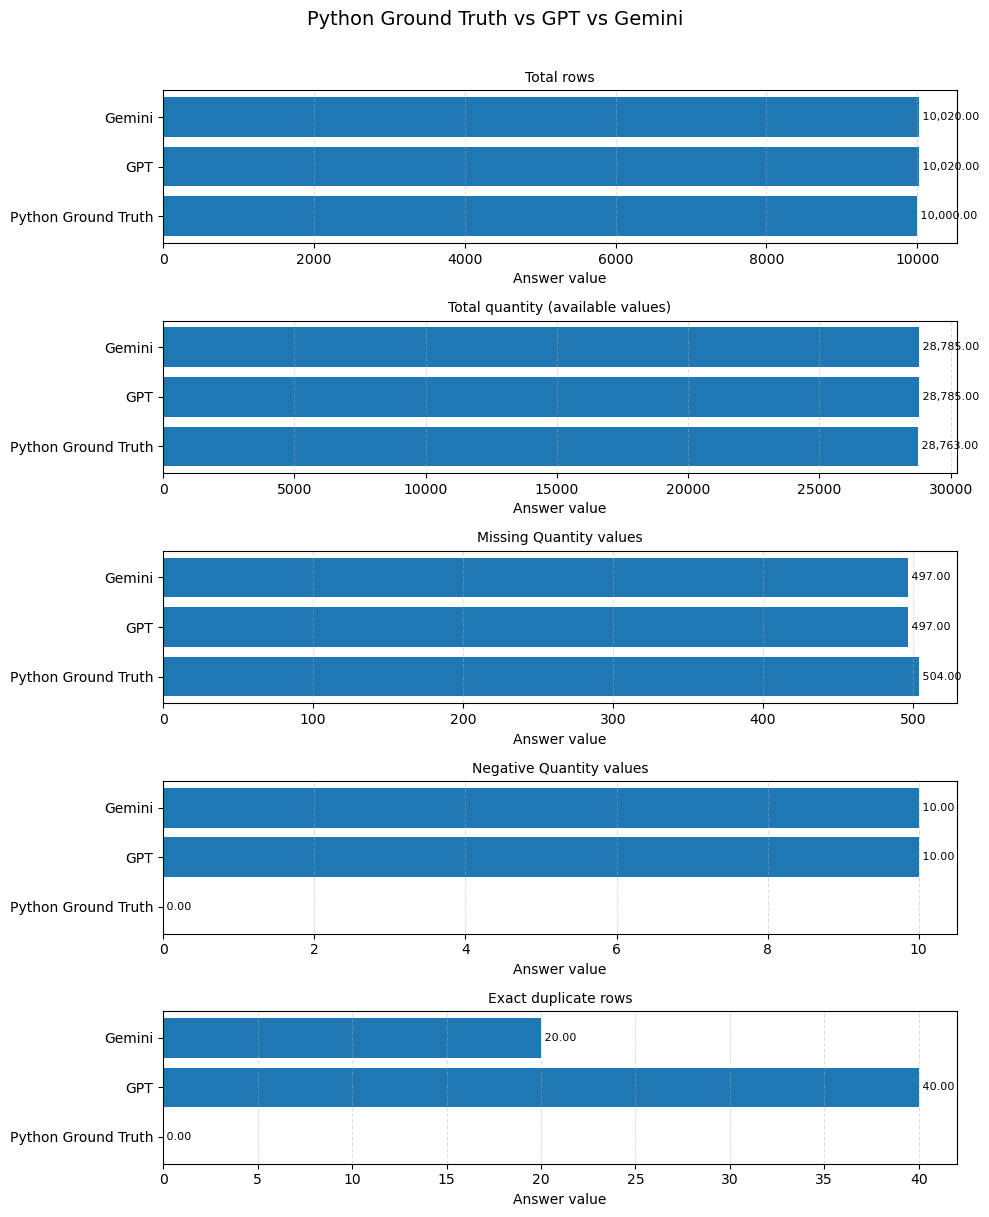

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load comparison results
df = pd.read_csv(r"C:\Users\Admin\llm_comparison_results.csv")

# Select metrics for the first graph
selected_metrics = [
    "Total rows",
    "Total quantity (available values)",
    "Missing Quantity values",
    "Negative Quantity values",
    "Exact duplicate rows"
]

plot_df = df[df["Question"].isin(selected_metrics)].copy()

# Convert answers to numeric values
answer_cols = ["Python_Answer", "GPT_Answer", "Gemini_Answer"]

for col in answer_cols:
    plot_df[col] = pd.to_numeric(plot_df[col], errors="coerce")

# Keep the selected metrics in the intended order
plot_df["Question"] = pd.Categorical(
    plot_df["Question"],
    categories=selected_metrics,
    ordered=True
)
plot_df = plot_df.sort_values("Question")

# Create one subplot per metric
fig, axes = plt.subplots(
    nrows=len(plot_df),
    ncols=1,
    figsize=(10, 12)
)

models = ["Python_Answer", "GPT_Answer", "Gemini_Answer"]
labels = ["Python Ground Truth", "GPT", "Gemini"]

for ax, (_, row) in zip(axes, plot_df.iterrows()):
    values = [row[col] for col in models]

    ax.barh(labels, values)
    ax.set_title(str(row["Question"]), fontsize=10)
    ax.set_xlabel("Answer value")
    ax.grid(axis="x", linestyle="--", alpha=0.4)

    # Display the values beside each bar
    for i, value in enumerate(values):
        if pd.notna(value):
            ax.text(value, i, f" {value:,.2f}", va="center", fontsize=8)

plt.suptitle(
    "Python Ground Truth vs GPT vs Gemini",
    fontsize=14,
    y=1.01
)
plt.tight_layout()
plt.savefig("first_graph_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

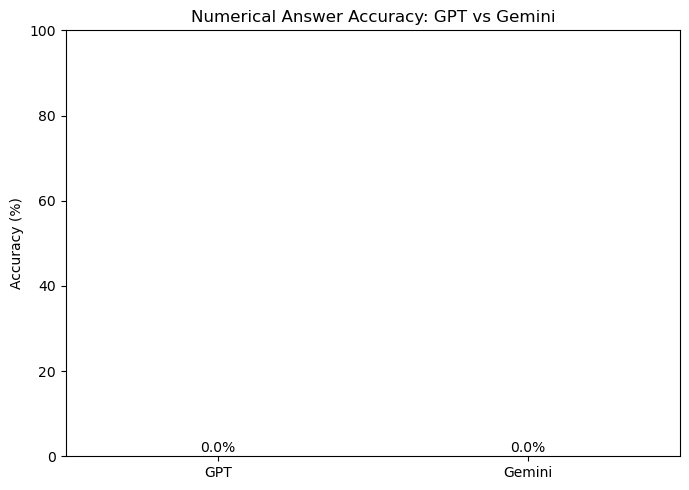

In [17]:

models = ["GPT", "Gemini"]
accuracies = []

for model in models:
    result_col = f"{model}_Match"

    if result_col not in comparison.columns:
        raise ValueError(
            f"{result_col} is missing. Run the comparison cell first."
        )

    evaluated = comparison[
        comparison[result_col].isin(["Correct", "Incorrect"])
    ]

    if len(evaluated) == 0:
        accuracy = np.nan
    else:
        accuracy = (
            evaluated[result_col].eq("Correct").mean() * 100
        )

    accuracies.append(accuracy)

plt.figure(figsize=(7, 5))
bars = plt.bar(models, accuracies)

plt.title("Numerical Answer Accuracy: GPT vs Gemini")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for bar, value in zip(bars, accuracies):
    if not np.isnan(value):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            value + 1,
            f"{value:.1f}%",
            ha="center"
        )

plt.tight_layout()
plt.savefig("second_graph_comparison.png", dpi=300, bbox_inches="tight")
plt.show()